
# Lab 8: Monte Carlo Markov Chain (MCMC)

**Exercise 1**:

* 1. Compute $\int_0^4 x^{1/2} dx$ and compare with an analytic result.
* 2.  Compute the double integral of $x\,y^2$ over the box x ranging from $0$ to $2$ and $y$ ranging from $0$ to $1$. That is,

$$\int_{x=0}^{x=2} \int_{y=0}^{y=1} xy^2 dy dx$$

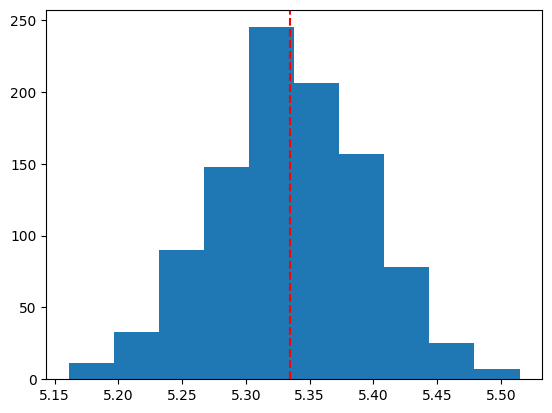

np.float64(-0.001566644394173089)

In [99]:
import numpy as np
import matplotlib.pyplot as plt

f = lambda x: x**(1/2)

datos = 1000
def monte(a,b,f,N):
  lis = np.random.uniform(a,b,size = (N))
  inte = 0
  for i in range(N):
    inte += f(lis[i])
  return (b-a)*(inte/N)

hi = []
can = 1000
for i in range(can):
  hi.append(monte(0,4,f,datos))
plt.hist(hi)
plt.axvline(np.mean(hi), color = "red", linestyle = '--')
plt.show()

from scipy import integrate
(integrate.quad(f,0,4)[0]-np.mean(hi))

In [100]:
f1 = lambda x: x
f2 = lambda y: y**2
def montedoble(a,b,a1,b1,f,f1,N):
  lis = np.random.uniform(a,b,size = (N))
  lis1 = np.random.uniform(a1,b1,size = (N))
  inte1 = 0
  inte2 = 0
  for i in range(N):
    inte1 += f(lis[i])
    inte2 += f1(lis1[i])
  return (b-a)*(inte1/N)*(inte2/N)*(b1-a1)
h1 = []
for i in range(can):
  h1.append(montedoble(0,2,0,1,f1,f2,datos))
integral = np.mean(h1)
abs(integral - 2/3) #2/3 es el valor de la integral original
# nota: este caso se hizo el 2d de esa menera ya que la funcion es seperable, no se hizo de manera general ya que no me pidieron la fomra general :v

np.float64(0.000784858133401678)

**Exercise 2**:

Read about the Ising's model 1D, 2D and 3D.

## Modelo de Ising 2D

Como aplicación de la distribución canónica en `Física estadística` tenemos el **modelo de Ising**.
Para el caso de un material paramagnético de átomos de spin $1/2$ y momento magnetico $\mu_0$ en presencia de un campo magnético externo $H$, se ha determinado experimentalmente que la magnetización media depende del campo magnético y la temperatura del material (https://en.wikipedia.org/wiki/Ising_model).

Considere un sistema compuesto por $N$ átomos no interactuantes en un material 2D, a una temperatura $T$ y en presencia de un campo magnético externo $H$ que está orientado en cierta dirección fija respecto al material.

<img src="https://upload.wikimedia.org/wikipedia/commons/f/fe/2D_ising_model_on_lattice.svg" width="550">

1. Realizar la simulación de este sistema con el método de **Metrópolis Monte Carlo** (ver notebook). Visitar todos los
posibles spines de la red cristalina del material e intentear inversiones bajo condiciones adecuadas de energía y estabilidad del sistema. *Considere interacción con los primeros vecinos*.

2. Graficar la Magnetización media del material vs el campo magnetico para tres temperaturas reducidas (H/T) con $T=\{5,10,15\}$ K (Kelvin) y un campo variable $-30\,T < H < +30\,T$.  

#Punto 1

In [101]:
N1 = 6
n = 5
rango_H = 100
T = [5,10,15]
H = np.linspace(-30,30,rango_H)
rng = np.random.default_rng() #construccion de una matriz con entradas aleatorias que asigna menos 1 o 1 de manera aleatoria
matriz = rng.choice([-1, 1], size=(N1, n))
matriz

array([[-1,  1,  1, -1, -1],
       [ 1,  1,  1,  1,  1],
       [ 1,  1, -1,  1,  1],
       [ 1,  1,  1, -1, -1],
       [ 1, -1, -1,  1, -1],
       [-1, -1, -1,  1,  1]])

In [102]:
import random
J = 1
muo = 1
K_B = 1

def vecinos(matriz,i,j):
  if j+1 < len(matriz[0]) and i+1 < len(matriz):
    return matriz[i][j+1]+matriz[i][j-1]+matriz[i+1][j]+matriz[i-1][j]
  elif j+1 == len(matriz[0]) and i+1 == len(matriz):
    return matriz[i][0]+matriz[i][j-1]+matriz[0][j]+matriz[i-1][j]
  elif j+1 == len(matriz[0]):
    return matriz[i][0]+matriz[i][j-1]+matriz[i+1][j]+matriz[i-1][j]
  elif i+1 == len(matriz):
    return matriz[i][j+1]+matriz[i][j-1]+matriz[0][j]+matriz[i-1][j]


deEi = lambda i,j,H : (2*matriz[i][j])*(J*vecinos(matriz,i,j)+muo*H)

def metropolis(matriz,i,j,H,T):
  A = np.minimum(1,np.exp((-deEi(i,j,H))/(K_B*T)))
  B = random.uniform(0,1)
  if A == 1:
    return -matriz[i][j]
  elif A>=B:
    return -matriz[i][j]
  else:
    return matriz[i][j]

Text(0.5, 0, 'H (campo magnetico)')

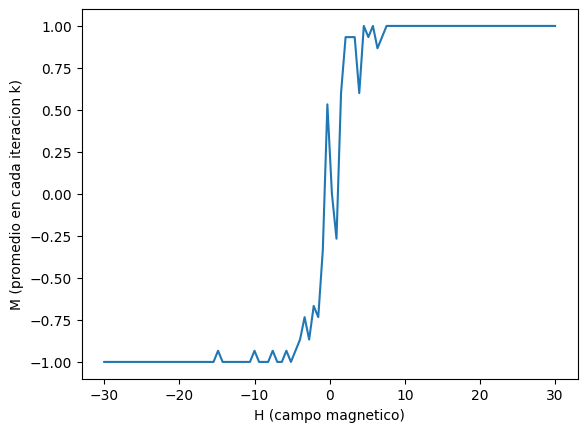

In [103]:
# primer T = 5
M = []
for k in range(len(H)):
  for i in range(len(matriz)):
    for j in range(len(matriz[0])):
      matriz[i][j] = metropolis(matriz,i,j,H[k],T[0])
  m_instantanea = np.sum(matriz) / (len(matriz) * len(matriz[0]))
  M.append(m_instantanea)
plt.plot(H,M)
plt.ylabel("M (promedio en cada iteracion k)")
plt.xlabel("H (campo magnetico)")

Text(0.5, 0, 'H (campo magnetico)')

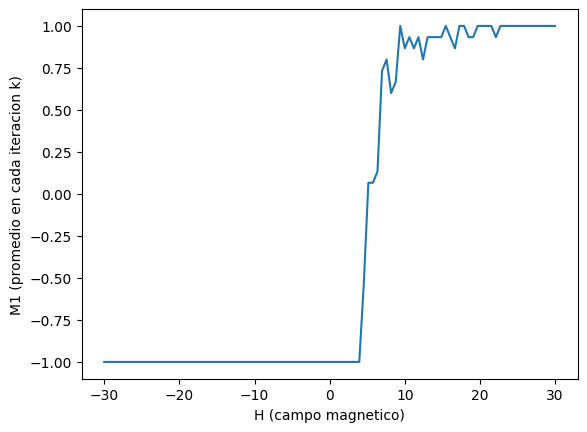

In [104]:
# para T=10

rng = np.random.default_rng() #construccion de una matriz1 con entradas aleatorias que asigna menos 1 o 1 de manera aleatoria
matriz1 = rng.choice([-1, 1], size=(N1, n))
M1 = []
deEi = lambda i,j,H : (2*matriz1[i][j])*(J*vecinos(matriz1,i,j)+muo*H)
for k in range(len(H)):
  for i in range(len(matriz1)):
    for j in range(len(matriz1[0])):
      matriz1[i][j] = metropolis(matriz1,i,j,H[k],T[1])
  m_instantanea = np.sum(matriz1) / (len(matriz1) * len(matriz1[0]))
  M1.append(m_instantanea)
plt.plot(H,M1)
plt.ylabel("M1 (promedio en cada iteracion k)")
plt.xlabel("H (campo magnetico)")

Text(0.5, 0, 'H (campo magnetico)')

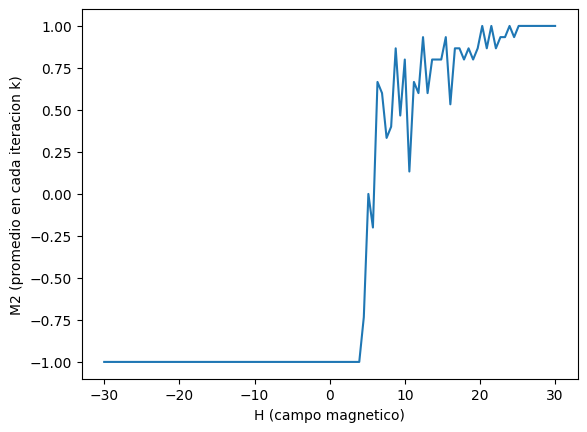

In [105]:
# para T=15

rng = np.random.default_rng() #construccion de una matriz2 con entradas aleatorias que asigna menos 1 o 1 de manera aleatoria
matriz2 = rng.choice([-1, 1], size=(N1, n))
M2 = []
deEi = lambda i,j,H : (2*matriz[i][j])*(J*vecinos(matriz2,i,j)+muo*H)
for k in range(len(H)):
  for i in range(len(matriz2)):
    for j in range(len(matriz2[0])):
      matriz2[i][j] = metropolis(matriz2,i,j,H[k],T[2])
  m_instantanea = np.sum(matriz2) / (len(matriz2) * len(matriz2[0]))
  M2.append(m_instantanea)
plt.plot(H,M2)
plt.ylabel("M2 (promedio en cada iteracion k)")
plt.xlabel("H (campo magnetico)")